In [4]:
!pip install gym_bandits

In [12]:
import gym
import gym_bandits
import numpy as np
import warnings
import matplotlib.pyplot as plt

In [8]:
warnings.filterwarnings("ignore", category=DeprecationWarning)

base_env = gym.make('MultiarmedBandits-v0')
env=base_env.unwrapped
print(env.action_space)

n_arms = env.action_space.n
num_episodes = 500

epsilon = 0.1

q_values = np.zeros(n_arms)
counts = np.zeros(n_arms)
reward_sums = np.zeros(n_arms)

all_rewards = []
action_history = []

Discrete(10)


In [9]:
for episode in range(num_episodes):
    env.reset()

    if np.random.rand() < epsilon:
        action = env.action_space.sample()
    else:
        action = np.argmax(q_values)

    observation, reward, done, info = env.step(action)

    counts[action] += 1
    reward_sums[action] += reward

    q_values[action] = reward_sums[action] / counts[action]

    all_rewards.append(reward)
    action_history.append(action)

env.close()

In [10]:
print("Estimated Q-values for each arm:", np.round(q_values, 2))
print("Number of times each arm was selected:", counts.astype(int))
print("Average reward over all episodes:", round(np.mean(all_rewards), 3))

Estimated Q-values for each arm: [-0.   -0.3  -0.05  0.   -0.29 -0.24 -0.11 -0.25  0.08 -0.17]
Number of times each arm was selected: [213   6  10 135   6   9  30  35  45  11]
Average reward over all episodes: -0.034


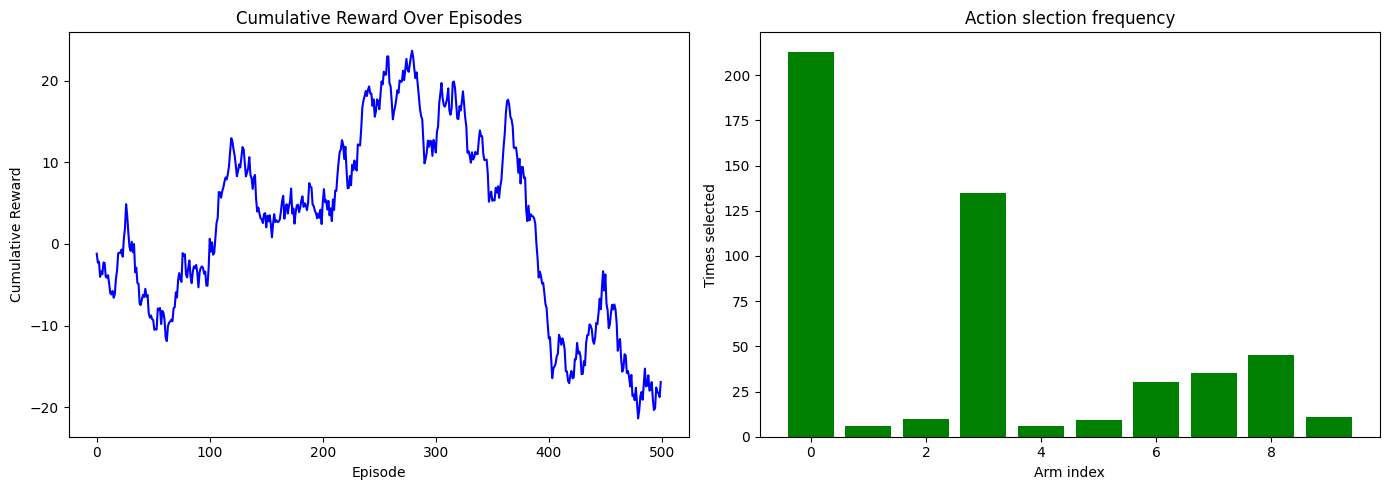

In [13]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(np.cumsum(all_rewards), color='blue')
plt.title("Cumulative Reward Over Episodes")
plt.xlabel("Episode")
plt.ylabel("Cumulative Reward")

plt.subplot(1, 2, 2)
plt.bar(np.arange(n_arms), counts, color='green')
plt.title("Action slection frequency")
plt.xlabel("Arm index")
plt.ylabel("Times selected")

plt.tight_layout()
plt.show()